# The light field camera: focus after the exposure

A camera sensor adds up all light that reaches a pixel, whatever part of
the lens it came through. That direction is what decides where the point
is in focus, and once it is summed it is lost. A light field (plenoptic)
camera keeps it. A microlens array sits where the sensor would be, and the
sensor moves back by one microlens focal length. Every microlens then
images the aperture of the main lens onto the small block of pixels
behind it, so each pixel records the light that reaches one place (its
microlens) from one part of the aperture. The camera samples the 4D light
field $L(x, y, u, v)$. The Lytro cameras (2012 and 2014) worked this way,
after Ng et al. (2005). The idea goes back to Lippmann's integral
photography (1908) and Adelson and Wang's plenoptic camera (1992).

This notebook covers:

1. the plenoptic camera and its raw image of a scene with three planes,
   and why the F-numbers of the main lens and of the microlenses must
   match,
2. the sub-aperture views that the pixels form, the parallax between them,
   and depth from that parallax compared with theory,
3. refocusing after the exposure by shifting and adding the views: its
   sharpness and its range compared with theory, and the light it saves
   over stopping down,
4. the trade-off between positions and directions on a fixed sensor,
5. a real main lens, the 50 mm double Gauss of notebook 90, whose exit
   pupil the microlenses image off centre.

The module `pyoptics.lightfield` holds the camera model, a ray sampled
renderer of scenes made of textured planes, and the light field
operations.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

from pyoptics import lightfield as lf
from pyoptics import photography as ph
from pyoptics import sensor as se
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

# the camera: a 50 mm f/4 main lens focused at 1 m, 120 x 120 microlenses of 0.1 mm,
# 7 x 7 pixels behind each (840 x 840 pixels of 14 um)
cam = lf.plenoptic_camera(focal_length=50.0, f_number=4.0, focus_distance=1000.0, pitch=0.1,
                          n_pixels=7, n_lenslets=120)
n = cam.n_pixels
cen = (n - 1)//2                      # index of the central pixel / view
cam64 = cam._replace(n_lenslets=64)   # a smaller sensor for the measurements on single planes
print("main lens: f = %.0f mm, f/%.0f, D = %.1f mm, focused at %.0f mm, image distance v = %.2f mm"
      % (cam.focal_length, cam.f_number, cam.aperture, cam.focus_distance, cam.image_distance))
print("microlenses: pitch %.2f mm, f_m = %.3f mm (f/%.2f, matched to v/D), %d x %d"
      % (cam.pitch, cam.microlens_focal_length, cam.microlens_focal_length/cam.pitch,
         cam.n_lenslets, cam.n_lenslets))
print("sensor: %d x %d pixels of %.2f um, %d x %d per microlens"
      % (n*cam.n_lenslets, n*cam.n_lenslets, 1e3*lf.pixel_pitch(cam), n, n))


def upright(img):
    """The camera image is upside down; turn it like a camera display."""
    return img[::-1, ::-1]


def white_scene(a, b):
    return 1.0, 1.0


def render(camera, layers, samples=16, seed=1):
    """Raw image and flat fielded views; the white image uses the same rays."""
    white = lf.render_raw(camera, [lf.Layer(1000.0, white_scene)], samples=samples,
                          rng=np.random.default_rng(seed))
    raw = lf.render_raw(camera, layers, samples=samples, rng=np.random.default_rng(seed))
    return raw, white, lf.subaperture_views(raw, camera.n_pixels, white)


# the scene: a brick wall at 3 m, a Siemens star at 1 m (in focus), a chequered card at 0.6 m;
# textures are functions of the angles a = x/s, b = y/s (rad)
shade = 0.3 + 0.35*np.random.default_rng(0).random((64, 64))


def brick_wall(a, b):
    row = np.floor(b/0.012).astype(int)
    a2 = a + 0.012*(row % 2)
    col = np.floor(a2/0.024).astype(int)
    mortar = (np.mod(a2, 0.024) < 0.0015) | (np.mod(b, 0.012) < 0.0015)
    return np.where(mortar, 0.85, shade[row % 64, col % 64]), 1.0


def siemens_star(a, b, centre=(0.03, 0.02), radius=0.055, spokes=24):
    x, y = a - centre[0], b - centre[1]
    val = np.where(np.cos(spokes*np.arctan2(y, x)) > 0, 0.9, 0.1)
    return val, (np.hypot(x, y) < radius).astype(float)


def checker_card(a, b, box=(-0.1, -0.015, -0.1, -0.025), square=0.008):
    inside = (a > box[0]) & (a < box[1]) & (b > box[2]) & (b < box[3])
    val = np.where((np.floor(a/square) + np.floor(b/square)) % 2 == 0, 0.95, 0.15)
    return val, inside.astype(float)


scene = [lf.Layer(600.0, checker_card), lf.Layer(1000.0, siemens_star), lf.Layer(3000.0, brick_wall)]
names = ["card, 0.6 m", "star, 1 m", "wall, 3 m"]

# a random texture for measurements on single planes
_r = np.random.default_rng(3).random((512, 512))
_g = ndimage.gaussian_filter(_r, 2, mode="wrap") - ndimage.gaussian_filter(_r, 6, mode="wrap")
_g = 0.5 + 0.5*np.tanh(2*_g/_g.std())


def noise_texture(a, b):
    return ndimage.map_coordinates(_g, [b/0.001, a/0.001], order=1, mode="wrap"), 1.0

main lens: f = 50 mm, f/4, D = 12.5 mm, focused at 1000 mm, image distance v = 52.63 mm
microlenses: pitch 0.10 mm, f_m = 0.421 mm (f/4.21, matched to v/D), 120 x 120
sensor: 840 x 840 pixels of 14.40 um, 7 x 7 per microlens


## 1. The plenoptic camera

The main lens (focal length $f$, aperture $D$, at $f/N$) is focused at the
distance $s_f$ and images it onto the microlens array at
$v = f s_f/(s_f - f)$. The microlenses have the pitch $p$ and the focal
length $f_m$, and the sensor sits in their focal plane. A ray that leaves
the aperture at $u$ and crosses the array at $x$, inside the microlens
centred at $c$, reaches the sensor at

$$x_s = c + f_m\,\frac{x - u}{v}.$$

The pixel under a microlens therefore says where the ray left the
aperture, $u \approx -(x_s - c)\,v/f_m$, reversed. The microlens says
where it arrived, $x \approx c$. With $n \times n$ pixels per microlens
the camera records $n^2$ directions at each of the microlens positions.

`lf.render_raw()` samples every pixel with random rays: a point on the
pixel and a point on a microlens fix $u$, and rays that miss the circular
aperture carry no light. Each ray is traced back through the conjugate
point of $x$ at $s_f$ into the scene, a stack of textured planes, where
the nearest opaque plane gives its radiance. Here the main lens is a
50 mm f/4 focused at 1 m. Behind it sit 120 × 120 microlenses of 0.1 mm
and 7 × 7 pixels each. The scene is a Siemens star at 1 m (in focus), a
chequered card at 0.6 m and a brick wall at 3 m.

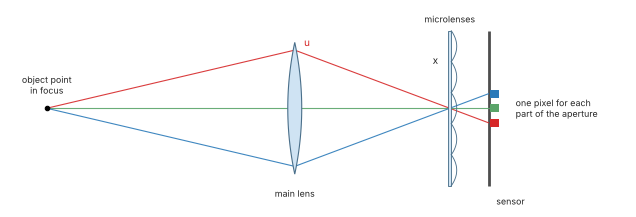

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.4))
sketch.plenoptic_camera(ax)
plt.show()

raw image 840 x 840 pixels rendered with 11.3 M rays in 4.6 s


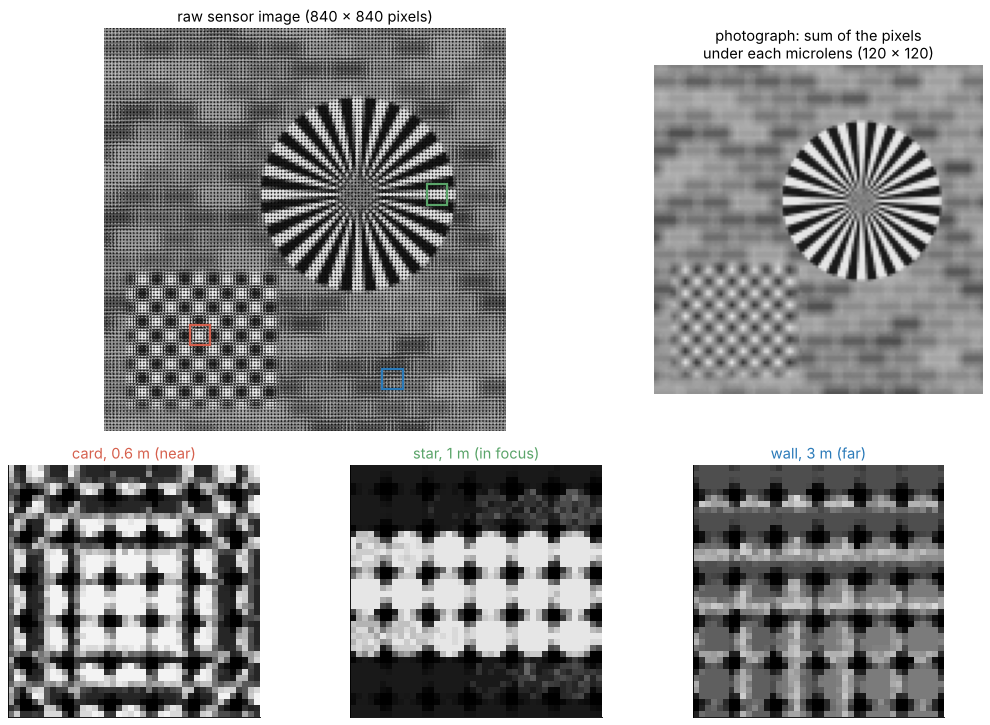

In [3]:
t = time.time()
raw, white, views = render(cam, scene)
photo = lf.refocus(views, 0.0)
print("raw image %d x %d pixels rendered with %.1f M rays in %.1f s"
      % (raw.shape[0], raw.shape[1], 16*raw.size/1e6, time.time() - t))

v, q = cam.image_distance, lf.pixel_pitch(cam)
N_tot = raw.shape[0]


def pixel_of(a, b):
    """Upright pixel (row, col) of the chief ray from the angles (a, b)."""
    return int(N_tot/2 - b*v/q), int(N_tot/2 + a*v/q)


crops = [("card, 0.6 m (near)", (-0.06, -0.06)), ("star, 1 m (in focus)", (0.075, 0.02)),
         ("wall, 3 m (far)", (0.05, -0.085))]
fig = plt.figure(figsize=(13, 9.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.6, 1])
ax = fig.add_subplot(gs[0, 0:2])
ax.imshow(upright(raw), cmap="gray", vmin=0, vmax=1)
ax.set_title("raw sensor image (840 x 840 pixels)")
for k, (title, ab) in enumerate(crops):
    r, c = pixel_of(*ab)
    ax.add_patch(plt.Rectangle((c - 21, r - 21), 42, 42, fill=False, color=[RED, GREEN, BLUE][k], lw=2))
ax.axis("off")
ax = fig.add_subplot(gs[0, 2])
ax.imshow(upright(photo), cmap="gray", vmin=0, vmax=1)
ax.set_title("photograph: sum of the pixels\nunder each microlens (120 x 120)")
ax.axis("off")
for k, (title, ab) in enumerate(crops):
    r, c = pixel_of(*ab)
    ax = fig.add_subplot(gs[1, k])
    ax.imshow(upright(raw)[r - 21:r + 21, c - 21:c + 21], cmap="gray", vmin=0, vmax=1,
              interpolation="nearest")
    ax.set_title(title, color=[RED, GREEN, BLUE][k])
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

The raw image is a mosaic of small disks, one per microlens. Adding the
pixels under each microlens gives a conventional photograph with one
pixel per microlens (top right). In it the star is sharp and the card and
the wall are blurred, as at f/4. The crops show what the disks hold. On
the star, which is in focus on the microlenses, each disk is uniform,
because all its light comes from one point of the scene. On the card and
on the wall, which are out of focus, each disk holds a small image of the
part of the scene around it. The card's small images have the same
orientation as the photograph, because the card's image plane lies behind
the array. The wall's are turned by 180°, because the wall's image plane
lies in front of it.

The disks only just touch because the F-numbers match. Every disk is an
image of the main lens aperture with the diameter $f_m D/v = p\,N_m/N_w$
(for microlens F-number $N_m = f_m/p$ and the working F-number
$N_w = v/D$ of the main lens). The microlenses here are designed for f/4
at 1 m, $N_m = v/D = 4.21$.

main lens   image diameter / pitch      light from neighbouring microlenses
            theory   measured            theory   rendered


  f/2.8       1.417      -                  36.6 %    36.6 %


  f/4.0       0.992    0.995                 0.0 %     0.0 %


  f/8.0       0.496    0.503                 0.0 %     0.0 %


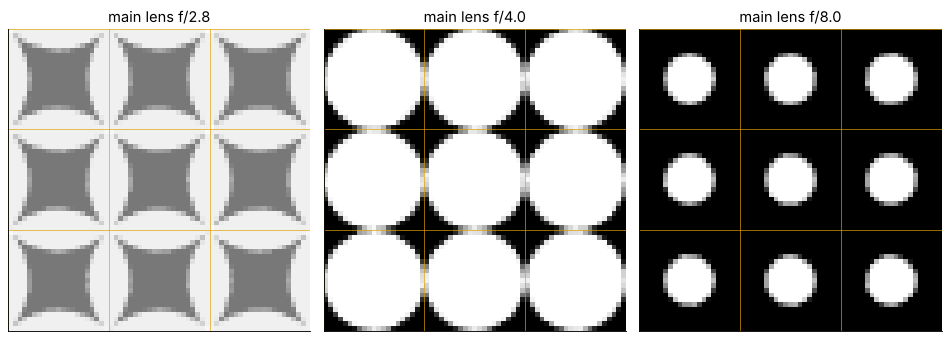

In [4]:
# microlens images of a white scene with the main lens at f/2.8, f/4 (matched) and f/8;
# the microlenses stay at f/4.21
fig, axs = plt.subplots(1, 3, figsize=(12, 4.3))
print("main lens   image diameter / pitch      light from neighbouring microlenses")
print("            theory   measured            theory   rendered")
for ax, N in zip(axs, (2.8, 4.0, 8.0)):
    c2 = lf.plenoptic_camera(50.0, N, 1000.0, 0.1, 21, 6,
                             microlens_f_number=cam.microlens_focal_length/cam.pitch)
    w1 = lf.render_raw(c2, [lf.Layer(1000.0, white_scene)], samples=64, rng=np.random.default_rng(2))
    w0 = lf.render_raw(c2, [lf.Layer(1000.0, white_scene)], samples=64, rng=np.random.default_rng(2),
                       neighbours=0)
    # diameter of the microlens image from its second moment (central 4 x 4 microlenses,
    # light of the own microlens only)
    q2 = lf.pixel_pitch(c2)
    blocks = w0.reshape(6, 21, 6, 21)[1:5, :, 1:5].transpose(0, 2, 1, 3).reshape(-1, 21, 21).mean(0)
    yy, xx = (np.mgrid[0:21, 0:21] - 10)*q2
    m2 = (blocks*(xx**2 + yy**2)).sum()/blocks.sum() + q2**2/6
    d_meas = 2*np.sqrt(2*m2)/(21*q2)
    d_th = c2.microlens_focal_length*c2.aperture/c2.image_distance/(21*q2)
    cross = 1 - w0[21:-21, 21:-21].sum()/w1[21:-21, 21:-21].sum()
    cross_th = 1 - se.disk_square_overlap(0, 0, d_th/2, 0.5)
    print("  f/%-4.1f      %.3f    %s               %5.1f %%   %5.1f %%"
          % (N, d_th, "%.3f" % d_meas if d_th < 1 else "  -  ", 100*max(cross_th, 0),
             100*max(cross, 0)))
    ax.imshow(w1[21:84, 21:84], cmap="gray", vmin=0, vmax=w1.max(), interpolation="nearest")
    for k in range(4):
        ax.axhline(21*k - 0.5, color=ORANGE, lw=0.6)
        ax.axvline(21*k - 0.5, color=ORANGE, lw=0.6)
    ax.set_title("main lens f/%.1f" % N)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

With the main lens opened to f/2.8 the disks are 1.42 microlens pitches
wide and overlap. Then 36.6 % of the light reaching the sensor through a
microlens lands under its neighbours, exactly the fraction of the disk
outside its square (`sensor.disk_square_overlap()`). Those pixels mix
directions and positions, so they are useless. Stopped down to f/8 the
disks shrink to half a pitch, and three quarters of the pixels stay dark.
The measured disk diameters agree with $f_m D/v$ to 1.5 %. This is why the
Lytro cameras had a fixed f/2 aperture.

The renderer puts the sensor pixels on a grid of pitch
$p(1 + f_m/v)/n$ rather than $p/n$ (`lf.pixel_pitch()`). Seen from the
centre of the main lens, the chief ray to a microlens at the height $c$
continues to $c(1 + f_m/v)$ on the sensor, so the disks lie on a grid
slightly larger than the microlens grid. Without this correction the
disks would walk off their pixel blocks across the sensor, and the views
below would mix directions. Section 5 returns to this with a real lens.

## 2. Sub-aperture views and parallax

Taking the same pixel $(i, j)$ from under every microlens gives an image
of 120 × 120 pixels. It is the picture taken through a small part of the
aperture, the square of side $\Delta u = D(1 + f_m/v)/n$ around
$u = -(j - c)\,\Delta u$ (`lf.subaperture_views()`, `lf.view_step()`).
These are 49 views from slightly different viewpoints on the 12.5 mm
aperture, a small stereo rig in one lens. Each view has the depth of field
of the aperture $D/n$, an f/28 lens.

A point at the distance $s$ is imaged at $v_s$. A ray from $u$ toward
that image point crosses the microlens array at
$x = x_0 + u\,(1 - v/v_s)$, so between neighbouring views the point moves
by the disparity

$$d = \left(1 - \frac{v}{v_s}\right)\frac{\Delta u}{p}
   = \frac{v\,\Delta u}{p}\left(\frac{1}{s} - \frac{1}{s_f}\right)$$

microlenses (`lf.disparity()`). The disparity is zero in the plane of
focus and linear in $1/s$. It is positive for nearer points and negative
for farther ones, down to $-v\,\Delta u/(p\,s_f)$ at infinity. The raw
images are divided by the raw image of a white scene, rendered with the
same rays, as cameras are calibrated with white images.

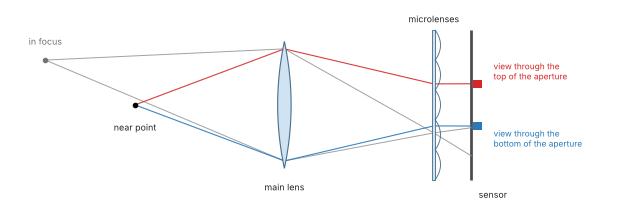

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.4))
sketch.subaperture_parallax(ax)
plt.show()

card, 0.6 m  disparity +0.632 microlenses per view, +3.79 across the aperture
star, 1 m    disparity +0.000 microlenses per view, +0.00 across the aperture
wall, 3 m    disparity -0.632 microlenses per view, -3.79 across the aperture


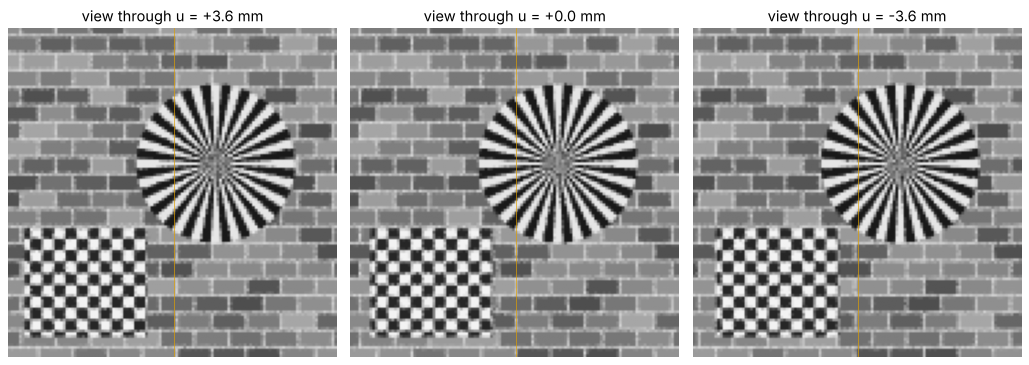

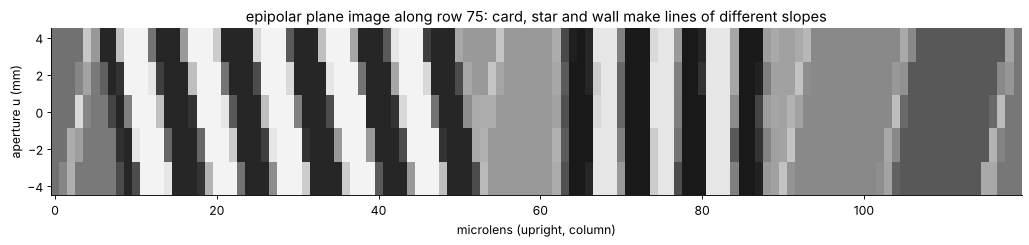

In [6]:
d_layers = lf.disparity(cam, [L.distance for L in scene])
for name, d in zip(names, d_layers):
    print("%-12s disparity %+.3f microlenses per view, %+.2f across the aperture"
          % (name, d, 6*d))

fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, j in zip(axs, (1, 3, 5)):
    # view column j sees the aperture at u = -(j - cen) D/n; upright the picture is turned,
    # so u > 0 (right half of the lens, seen from behind) is on the right
    ax.imshow(upright(views[cen, j]), cmap="gray", vmin=0, vmax=1)
    ax.set_title("view through u = %+.1f mm" % (-(j - cen)*lf.view_step(cam)))
    ax.axvline(60, color=ORANGE, lw=0.6)
    ax.axis("off")
plt.tight_layout()
plt.show()

# epipolar plane image: one row of the scene in all views of the central row
row = int(cam.n_lenslets/2 + 0.03*cam.image_distance/cam.pitch)     # upright row at b = -0.03
epi = np.array([upright(views[cen, j])[row] for j in range(n)])
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.imshow(np.repeat(epi[1:-1], 6, axis=0), cmap="gray", vmin=0, vmax=1, aspect="auto",
          extent=(-0.5, epi.shape[1] - 0.5, -2.5*lf.view_step(cam), 2.5*lf.view_step(cam)))
ax.set_xlabel("microlens (upright, column)")
ax.set_ylabel("aperture u (mm)")
ax.set_title("epipolar plane image along row %d: card, star and wall make lines of different slopes" % row)
plt.tight_layout()
plt.show()

The card moves by $4 \times 0.632 = 2.5$ microlenses between the outer
views shown and the wall by the same amount the other way, while the star
stays put (orange line). The epipolar plane image stacks one row of the
scene from all the views of the central row. Every point draws a line
whose slope is its disparity (Bolles et al. 1987). The star's lines are
vertical, and the card's and the wall's lean in opposite directions.
Where the card covers the wall, the card's lines cut off the wall's.

Next, single textured planes at twelve distances, each measured between
symmetric pairs of views. `lf.view_shift()` finds the whole pixel shift
by phase correlation and refines it with Gauss-Newton steps (Lucas and
Kanade 1981).

distance    disparity           distance from the disparity
  (mm)     theory  measured        (mm)      error
     350   +1.759   +1.755             351     +0.2 %
     400   +1.421   +1.418             401     +0.1 %
     500   +0.947   +0.945             501     +0.1 %
     600   +0.632   +0.629             601     +0.2 %
     750   +0.316   +0.314             751     +0.2 %
    1000   +0.000   -0.000            1000     +0.0 %
    1300   -0.219   -0.218            1299     -0.1 %
    2000   -0.474   -0.473            1995     -0.2 %
    3000   -0.632   -0.630            2984     -0.5 %
    6000   -0.789   -0.788            5935     -1.1 %
   20000   -0.900   -0.898           19277     -3.6 %
10000000   -0.947   -0.945          467029    -95.3 %
rms disparity error 0.002 microlenses per view
depth resolution for this error: 2.3 mm at 1 m, 21 mm at 3 m (s^2 times 2.3e-06 /mm)


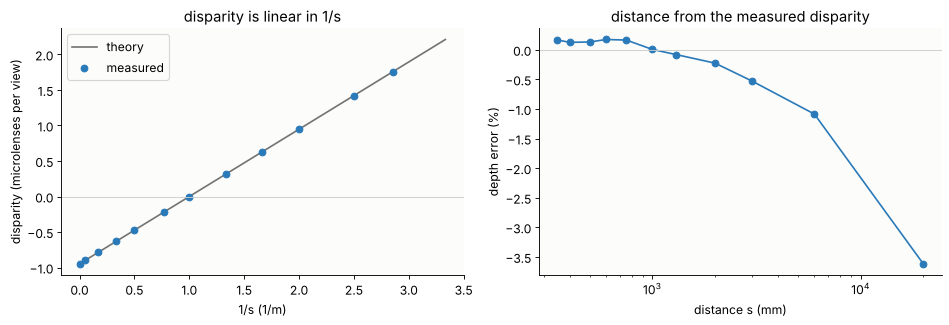

In [7]:
# disparity of textured planes at many distances, measured between
# symmetric pairs of views (`lf.view_shift()`), against d = (1 - v/v_s) D/(n p) = v D (1/s - 1/s_f)/(n p)
dist = np.array([350, 400, 500, 600, 750, 1000, 1300, 2000, 3000, 6000, 20000, 1e7])
d_th = lf.disparity(cam64, dist)
d_ms = []
for s in dist:
    _, _, V = render(cam64, [lf.Layer(s, noise_texture)])
    est = [lf.view_shift(V[cen, cen - k], V[cen, cen + k])[1]/(-2*k) for k in (1, 2, 3)]
    est += [lf.view_shift(V[cen - k, cen], V[cen + k, cen])[0]/(-2*k) for k in (1, 2, 3)]
    d_ms.append(np.mean(est))
d_ms = np.array(d_ms)
s_ms = lf.depth_from_disparity(cam64, d_ms)
print("distance    disparity           distance from the disparity")
print("  (mm)     theory  measured        (mm)      error")
for s, a, b, sm in zip(dist, d_th, d_ms, s_ms):
    if sm > 0:
        print("%8.0f   %+.3f   %+.3f      %10.0f   %+6.1f %%" % (s, a, b, sm, 100*(sm/s - 1)))
    else:
        print("%8.0f   %+.3f   %+.3f      beyond infinity" % (s, a, b))
dd = np.std(d_ms - d_th)
print("rms disparity error %.3f microlenses per view" % dd)
k = cam.image_distance*lf.view_step(cam)/cam.pitch
print("depth resolution for this error: %.1f mm at 1 m, %.0f mm at 3 m (s^2 times %.1e /mm)"
      % (1e6*dd/k, 9e6*dd/k, dd/k))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.linspace(0, 1/300, 200)
ax = axs[0]
ax.plot(1e3*x, k*(x - 1/cam.focus_distance), color=GREY, label="theory")
ax.plot(1e3/dist, d_ms, "o", color=BLUE, label="measured")
ax.axhline(0, color="0.8", lw=0.8)
ax.set_xlabel("1/s (1/m)")
ax.set_ylabel("disparity (microlenses per view)")
ax.legend()
ax.set_title("disparity is linear in 1/s")
ax = axs[1]
ax.semilogx(dist[:-1], 100*(s_ms[:-1]/dist[:-1] - 1), "o-", color=BLUE)
ax.axhline(0, color="0.8", lw=0.8)
ax.set_xlabel("distance s (mm)")
ax.set_ylabel("depth error (%)")
ax.set_title("distance from the measured disparity")
plt.tight_layout()
plt.show()

The measured disparity lies on the straight line of the theory, with an
rms deviation of 0.002 microlenses per view. Converted back to distance
(`lf.depth_from_disparity()`), it is right to 0.5 % from 0.35 m to 3 m.
The depth error grows as $s^2$: 2 mm at 1 m and 2 cm at 3 m for this
disparity error. At 20 m it is 4 %, and infinity cannot be told from
about 500 m. The baseline of a plenoptic camera is its aperture, 12.5 mm here,
so it measures depth only close up.

For a whole scene, `lf.disparity_map()` uses photo consistency (after Tao
et al. 2013). For each candidate disparity the views are shifted to bring
it into register, and where the candidate is right all views see the same
radiance. The variance across the views, averaged over 7 × 7 microlenses,
is smallest there. The views on the rim of the circular aperture see only
the inner part of their square, so their effective $u$ is nearer the
centre than the nominal one, and they would bias the result toward zero.
`lf.view_weights()` leaves them out, which leaves 29 of the 45 views.

disparity map of 120 x 120 microlenses in 1.4 s
card, 0.6 m  theory +0.632, median +0.630, within 0.1 of it: 100.0 % of 1184 microlenses
star, 1 m    theory +0.000, median +0.001, within 0.1 of it: 100.0 % of 2008 microlenses
wall, 3 m    theory -0.632, median -0.629, within 0.1 of it: 99.1 % of 6810 microlenses


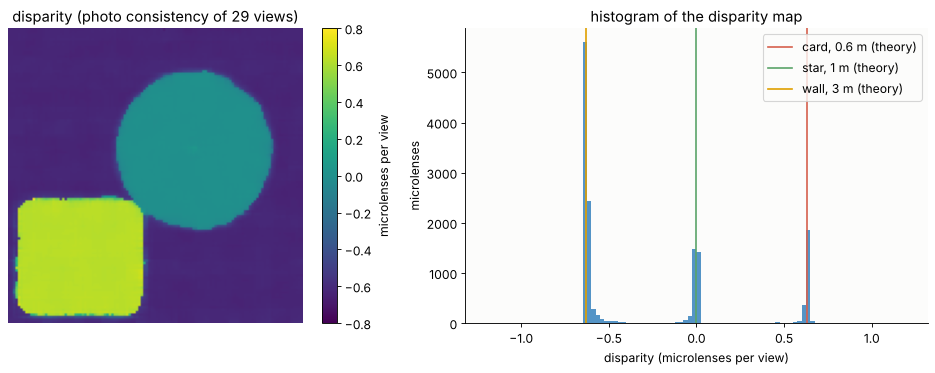

In [8]:
t = time.time()
cand = np.arange(-1.2, 1.2001, 0.05)
full = lf.view_weights(white, n)     # leave out the views cut by the rim of the aperture
dmap, cost = lf.disparity_map(views, cand, patch=7, aperture=full)
print("disparity map of %d x %d microlenses in %.1f s" % (dmap.shape + (time.time() - t,)))

# ground truth: the layer hit by the chief ray of every microlens
xc = (np.arange(cam.n_lenslets) + 0.5)*cam.pitch - cam.n_lenslets*cam.pitch/2
A, B = np.broadcast_arrays(-xc[None, :]/cam.image_distance, xc[:, None]/cam.image_distance)
truth = np.where(siemens_star(A, B)[1] > 0, 1, 2)
truth = np.where(checker_card(A, B)[1] > 0, 0, truth)
for k, name in enumerate(names):
    m = truth == k
    m = ndimage.binary_erosion(m, iterations=4)
    dk = dmap[m]
    print("%-12s theory %+.3f, median %+.3f, within 0.1 of it: %4.1f %% of %d microlenses"
          % (name, d_layers[k], np.median(dk), 100*np.mean(np.abs(dk - d_layers[k]) < 0.1), m.sum()))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
im = axs[0].imshow(upright(dmap), cmap="viridis", vmin=-0.8, vmax=0.8)
axs[0].set_title("disparity (photo consistency of %d views)" % full.sum())
axs[0].axis("off")
cb = plt.colorbar(im, ax=axs[0], fraction=0.046)
cb.set_label("microlenses per view")
ax = axs[1]
ax.hist(dmap.ravel(), bins=np.arange(-1.2, 1.21, 0.025), color=BLUE, alpha=0.8)
for k, name in enumerate(names):
    ax.axvline(d_layers[k], color=[RED, GREEN, ORANGE][k], lw=1.5, label="%s (theory)" % name)
ax.set_xlabel("disparity (microlenses per view)")
ax.set_ylabel("microlenses")
ax.legend()
ax.set_title("histogram of the disparity map")
plt.tight_layout()
plt.show()

The map separates the three planes. Each layer's median disparity lies
within 0.003 of the theory, and all of the card and the star and 99.1 %
of the wall lie within 0.1 of it. The errors sit at the occlusion edges
and on the uniform mortar and spokes, where no shift is better than
another.

## 3. Refocusing

A sensor placed at the virtual image plane $v_s$ of a point would collect
all rays of that point in one spot. In the light field these rays reach
view $(i, j)$ at the position shifted by the disparity $d(s)$ per view.
Shifting every view back by $(i - c, j - c)\,d$ and adding them computes
the photograph that sensor would have taken (`lf.refocus()`, Ng 2005).
Here the shifts are sub-pixel Fourier shifts. Refocusing on $d = 0$ gives
the conventional photograph of section 1.

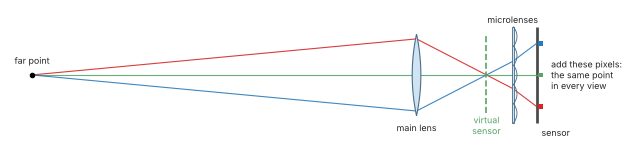

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.4))
sketch.light_field_refocus(ax)
plt.show()

refocused 20 images in 0.9 s


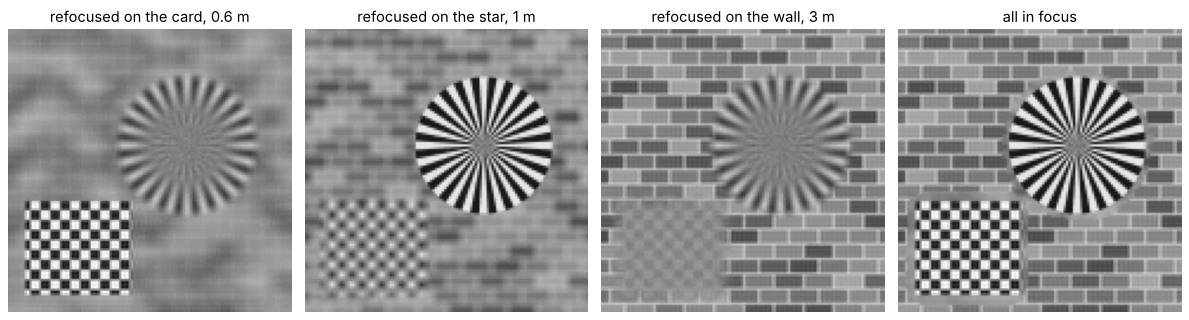

In [10]:
t = time.time()
refocused = [lf.refocus(views, d) for d in d_layers]
# all in focus: refocus on a stack of disparities and take every microlens from the image
# refocused on its own (smoothed) disparity
stack_d = np.arange(-0.8, 0.81, 0.1)
stack = np.array([lf.refocus(views, d) for d in stack_d])
dsm = ndimage.median_filter(dmap, 5)
idx = np.clip(np.round((dsm - stack_d[0])/0.1).astype(int), 0, len(stack_d) - 1)
allfocus = np.take_along_axis(stack, idx[None], 0)[0]
print("refocused %d images in %.1f s" % (3 + len(stack_d), time.time() - t))

fig, axs = plt.subplots(1, 4, figsize=(15, 4.4))
for ax, img, title in zip(axs, refocused + [allfocus],
                          ["refocused on the " + nm for nm in names] + ["all in focus"]):
    ax.imshow(upright(img), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

Each plane comes into focus in turn. Refocusing on a stack of
disparities and taking every microlens from the image focused on its own
disparity (from the map of section 2) gives an image sharp at all three
distances.

How sharp can a refocused image be? Every view integrates over one
microlens, a box of width $p$. Each pixel sees the part $\Delta u$ of the
aperture, which blurs a point with the disparity $d$ by a box of width
$\vert d\vert p$. The geometric MTF of the refocused image along $x$ is

$$\mathrm{MTF}(\nu) = \vert\mathrm{sinc}(\nu)\,\mathrm{sinc}(d\,\nu)\vert$$

with $\nu$ in cycles per microlens (`lf.refocused_mtf()`). It is the MTF
of a single view, the f/28 picture, but it gets the light of all of them.
A conventional photograph adds the views without shifting them, which
spreads them over $n\vert d\vert$ microlenses. For points within
$\vert d\vert \le 1$ the refocused blur stays within one microlens. This
refocus range is the depth of field of an f/$(nN)$ lens with the circle of
confusion $c = p$.

The test is a slanted edge rendered at eleven distances, refocused on its
own disparity, and measured with the slanted edge method of notebook 93
(`sensor.slanted_edge_mtf()`) at half the Nyquist frequency of the
microlens grid. Near the Nyquist frequency the Fourier shifts of the
undersampled views lose contrast, so the comparison stays below it.

distance   MTF(0.25 cycles/microlens)
  (mm)     refocused (theory)   centre view   photograph f/4 (theory)
     300     0.527  (0.511)        0.531         0.046  (0.008)
     350     0.639  (0.640)        0.666         0.037  (0.001)
     400     0.719  (0.725)        0.743         0.055  (0.066)
     450     0.786  (0.781)        0.796         0.072  (0.034)
     500     0.828  (0.820)        0.835         0.174  (0.148)
     600     0.859  (0.864)        0.872         0.007  (0.016)
     750     0.874  (0.891)        0.893         0.569  (0.550)
    1000     0.904  (0.900)        0.891         0.904  (0.900)
    1500     0.870  (0.891)        0.879         0.574  (0.550)
    3000     0.843  (0.864)        0.853         0.012  (0.016)
10000000     0.807  (0.820)        0.809         0.174  (0.148)
refocus range abs(d) <= 1: 486 mm to infinity
depth of field of f/28 with c = p = 0.10 mm: 484 mm to infinity
depth of field of the photograph at f/4 with c = p: 868 to 1179 mm


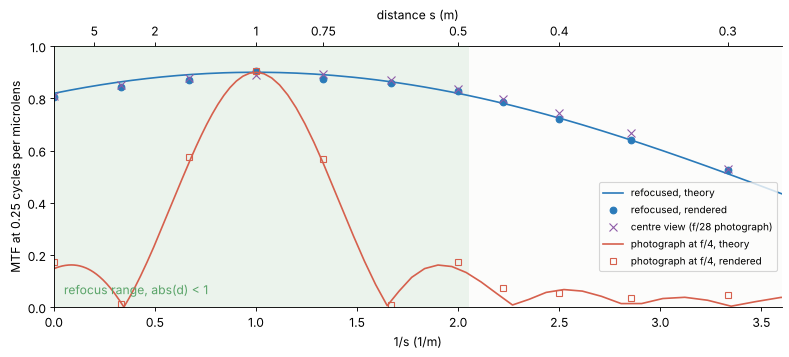

In [11]:
# sharpness of a refocused slanted edge against distance: MTF at 0.25 cycles per
# microlens (half the Nyquist frequency of the microlens grid)
ang = np.radians(5.0)


def edge(a, b):
    return 0.1 + 0.8*((a*np.cos(ang) - b*np.sin(ang)) > 0), 1.0


F0 = 0.25
dist_e = np.array([300, 350, 400, 450, 500, 600, 750, 1000, 1500, 3000, 1e7])
res = []
for s in dist_e:
    _, _, V = render(cam64, [lf.Layer(s, edge)], samples=32)
    d = lf.disparity(cam64, s)
    out = []
    for img in (lf.refocus(V, d), lf.refocus(V, 0.0), V[cen, cen]):
        f, m, _ = se.slanted_edge_mtf(img[8:-8, 8:-8])
        out.append(np.interp(F0, f, m))
    res.append(out)
res = np.array(res)
weights = lf.aperture_weights(V).sum(axis=0)

ss = np.geomspace(250, 1e7, 300)
dd = lf.disparity(cam64, ss)
th_ref = np.array([lf.refocused_mtf(F0, d) for d in dd])
th_conv = np.array([lf.refocused_mtf(F0, d, 0.0, weights) for d in dd])
print("distance   MTF(0.25 cycles/microlens)")
print("  (mm)     refocused (theory)   centre view   photograph f/4 (theory)")
for s, r in zip(dist_e, res):
    d = lf.disparity(cam64, s)
    print("%8.0f     %.3f  (%.3f)        %.3f         %.3f  (%.3f)"
          % (s, r[0], lf.refocused_mtf(F0, d), r[2], r[1], lf.refocused_mtf(F0, d, 0.0, weights)))

# refocus range: abs(d) <= 1, the depth of field of f/(n N) with c = p
near = lf.depth_from_disparity(cam, 1.0)
far = lf.depth_from_disparity(cam, -1.0)
far_txt = "infinity" if far < 0 or far > 1e9 else "%.0f mm" % far
dof = ph.dof_limits(cam.focal_length, n*cam.f_number, cam.pitch, cam.focus_distance)
print("refocus range abs(d) <= 1: %.0f mm to %s" % (near, far_txt))
print("depth of field of f/%.0f with c = p = %.2f mm: %.0f mm to %s"
      % (n*cam.f_number, cam.pitch, dof[0], "infinity" if not np.isfinite(dof[1]) or dof[1] < 0 else "%.0f mm" % dof[1]))
dof4 = ph.dof_limits(cam.focal_length, cam.f_number, cam.pitch, cam.focus_distance)
print("depth of field of the photograph at f/%.0f with c = p: %.0f to %.0f mm"
      % (cam.f_number, dof4[0], dof4[1]))

def distance_axis(ax):
    """Plot against 1/s, label the top axis with distances."""
    top = ax.secondary_xaxis("top", functions=(lambda x: x, lambda x: x))
    ds = np.array([0.3, 0.4, 0.5, 0.75, 1, 2, 5])
    top.set_xticks(1/ds)
    top.set_xticklabels(["%g" % d for d in ds])
    top.set_xlabel("distance s (m)")
    ax.set_xlabel("1/s (1/m)")
    ax.set_xlim(0, 3.6)


fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(1e3/ss, th_ref, color=BLUE, label="refocused, theory")
ax.plot(1e3/dist_e, res[:, 0], "o", color=BLUE, label="refocused, rendered")
ax.plot(1e3/dist_e, res[:, 2], "x", color=PURPLE, ms=8, label="centre view (f/28 photograph)")
ax.plot(1e3/ss, th_conv, color=RED, label="photograph at f/4, theory")
ax.plot(1e3/dist_e, res[:, 1], "s", color=RED, mfc="none", label="photograph at f/4, rendered")
ax.axvspan(0, 1e3/near, color=GREEN, alpha=0.1, lw=0)
ax.text(0.05, 0.05, "refocus range, abs(d) < 1", color=GREEN)
distance_axis(ax)
ax.set_ylabel("MTF at 0.25 cycles per microlens")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.12), fontsize=9)
plt.tight_layout()
plt.show()

The refocused edge follows the theory to within 0.02 in MTF from 0.3 m to
infinity, and its sharpness equals that of the centre view, the f/28
photograph. The f/4 photograph is sharp only around 1 m. Its MTF has
zeros and phase reversals (spurious resolution) where the blur box spans
4, 8, ... microlenses per cycle. The refocus range $\vert d\vert \le 1$
runs from 486 mm to infinity, against 484 mm to infinity for the depth of
field of an f/28 lens with $c = 0.1$ mm (`ph.dof_limits()`). The small
difference is the factor $1 + f_m/v$ in $\Delta u$. At f/4 the same
circle gives 0.87 to 1.18 m.

So the light field camera takes the picture that an f/28 lens would take,
at the resolution of the microlens grid, focused anywhere afterwards. What
it gains over simply stopping down is the light. Each refocused pixel
adds the photons of all the views. The next cell renders a grey plane
with photon noise (400 photons in a fully lit pixel) and compares the
noise in the centre view with that of the refocused image.

In [12]:
# photon noise: a grey plane at 0.6 m, 400 photons in a fully lit pixel
_, w_, V = render(cam64, [lf.Layer(600.0, lambda a, b: (0.5, 1.0))], samples=16)
raw_g = lf.render_raw(cam64, [lf.Layer(600.0, lambda a, b: (0.5, 1.0))], samples=16,
                      rng=np.random.default_rng(1))
noisy = np.random.default_rng(5).poisson(400*raw_g)/400
Vn = lf.subaperture_views(noisy, n, w_)
d = lf.disparity(cam64, 600.0)
ref = lf.refocus(Vn, d)[8:-8, 8:-8]
cv = Vn[cen, cen][8:-8, 8:-8]
ap = lf.aperture_weights(Vn)
trans = w_.reshape(64, n, 64, n).mean(axis=(0, 2))      # light in each view, centre = 1
trans = trans/trans[cen, cen]
gain = np.sqrt((ap**2).sum()**2/(ap**2/np.where(trans > 0, trans, 1)).sum())
print("noise: centre view (= f/%.0f photograph) %.4f, refocused %.4f, SNR gain %.2f"
      % (n*cam.f_number, cv.std(), ref.std(), cv.std()/ref.std()))
print("expected from the light in the %d views: %.2f (sqrt of the number of views: %.2f)"
      % (ap.sum(), gain, np.sqrt(ap.sum())))

noise: centre view (= f/28 photograph) 0.0352, refocused 0.0066, SNR gain 5.33
expected from the light in the 45 views: 5.62 (sqrt of the number of views: 6.71)


The refocused image is 5.3 times less noisy than the f/28 picture. That
is close to the 5.6 expected from the light in the views. It falls short
of $\sqrt{45} = 6.7$ because the rim views carry less light and the flat
field amplifies their noise. For the same exposure time an f/28 camera
would need $(28/4)^2 \approx 49$ times more light, about 5.6 stops, to
reach the same noise.

## 4. Positions against directions

The sensor has a fixed number of pixels. With $n \times n$ pixels per
microlens the photograph has $n^2$ times fewer pixels than the sensor, and
the refocus range grows in proportion to $n$, because the step
$\Delta u$ between the views shrinks with $n$. For the 840 × 840 sensor
of 14.4 µm pixels, the next cell compares microlenses of 1 (a
conventional camera), 3, 7 and 15 pixels. The resolution is the MTF50 of
the image refocused on each distance, capped at the Nyquist frequency
$1/2p$ of the microlens grid. The points are rendered slanted edges.

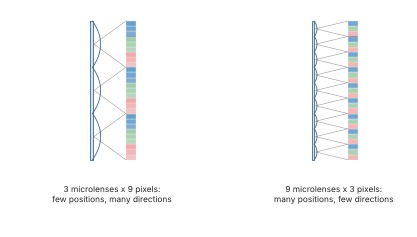

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sketch.plenoptic_tradeoff(ax)
plt.show()

  n   microlenses on 840 px   pixels each   peak resolution   refocus range abs(d) <= 1
  1           840               1          35.0 lp/mm         979 mm to 1022 mm
  3           280               9          11.7 lp/mm         837 mm to 1242 mm
  7           120              49           5.0 lp/mm         486 mm to infinity
 15            56             225           2.3 lp/mm         172 mm to infinity


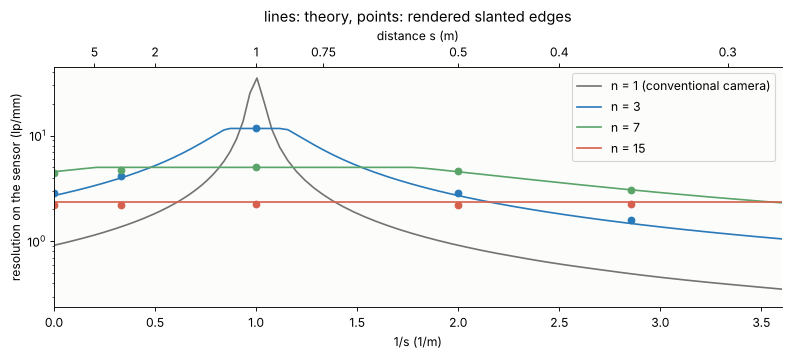

In [14]:
# the same sensor (pixels of p/7 = 14.3 um) behind microlenses of n pixels; resolution on the
# sensor = MTF50 of the image refocused on each distance, at most the Nyquist frequency 1/2p
q0 = cam.pitch/n
ns = [1, 3, 7, 15]
cams = {k: lf.plenoptic_camera(50.0, 4.0, 1000.0, k*q0, k, 48) for k in ns}
fq = np.linspace(0, 1.5, 601)


def resolution(c, s):
    m50 = lf.mtf50(fq, lf.refocused_mtf(fq, lf.disparity(c, s)))
    return min(m50, 0.5)/c.pitch


meas = {}
for k in (3, 7, 15):
    pts = []
    for s in (350, 500, 1000, 3000, 1e7):
        _, _, V = render(cams[k], [lf.Layer(s, edge)], samples=32 if k < 10 else 8)
        img = lf.refocus(V, lf.disparity(cams[k], s))[6:-6, 6:-6]
        f, m, _ = se.slanted_edge_mtf(img)
        pts.append((s, min(lf.mtf50(f, m), 0.5)/cams[k].pitch))
    meas[k] = np.array(pts)

fig, ax = plt.subplots(figsize=(10, 4.6))
cols = {1: GREY, 3: BLUE, 7: GREEN, 15: RED}
print("  n   microlenses on 840 px   pixels each   peak resolution   refocus range abs(d) <= 1")
for k in ns:
    c = cams[k]
    ax.semilogy(1e3/ss, [resolution(c, s) for s in ss], color=cols[k],
                label="n = %d%s" % (k, " (conventional camera)" if k == 1 else ""))
    if k in meas:
        ax.semilogy(1e3/meas[k][:, 0], meas[k][:, 1], "o", color=cols[k])
    near = lf.depth_from_disparity(c, 1.0)
    far = lf.depth_from_disparity(c, -1.0)
    print("%3d          %4d             %3d         %5.1f lp/mm       %5.0f mm to %s"
          % (k, 840//k, k*k, resolution(c, 1000.0), near,
             "infinity" if far < 0 or far > 1e9 else "%.0f mm" % far))
distance_axis(ax)
ax.set_ylabel("resolution on the sensor (lp/mm)")
ax.set_title("lines: theory, points: rendered slanted edges")
ax.legend()
plt.tight_layout()
plt.show()

Each resolution curve has a flat top at the microlens Nyquist frequency
and falls off once $\vert d\vert$ exceeds about 1. A conventional camera
resolves 35 lp/mm, but only within ±2 % of the focus distance at f/4. The
7 × 7 design keeps 5 lp/mm from 0.49 m to infinity. With 15 × 15 pixels
the range reaches 0.17 m, at 2.3 lp/mm. The rendered edges follow the
curves. The product of the two, spatial samples times directions, is
fixed by the sensor. The first Lytro camera had about 11 million pixels
behind roughly 330 × 330 microlenses, about 10 × 10 pixels each, and its
refocusable pictures had about 0.1 megapixels of real resolution.

The focused plenoptic camera (Lumsdaine and Georgiev 2009) moves the
microlenses so that they image the main lens image plane instead of the
aperture. It trades the other way, with more spatial resolution and a
depth dependent number of directions.

## 5. A real main lens

The microlenses image the exit pupil of the main lens, not its aperture
stop. A chief ray to the height $h$ in the image plane comes from the
centre of the exit pupil, which lies $L$ in front of the image plane. So
behind its microlens it lands at $f_m h/L$ from the centre. For a thin
lens $L = v$, and the pixel grid of section 1 is matched to it. For the
double Gauss at f/2.8 with matched f/2.8 microlenses, the exit pupil is
61.1 mm in front of the image plane, not 50 mm.

`lf.microlens_images()` traces rays from four field angles through the
lens. A thin microlens sends a ray of direction $(k_x, k_y, k_z)$ to
$f_m k_x/k_z$ from its centre, so the distribution of these points is the
microlens image of the exit pupil, vignetting included. The red square is
the microlens cell, and the dotted one is its neighbour on the side the
image walks toward.

exit pupil 61.1 mm in front of the image plane (a thin lens: 50.0 mm)


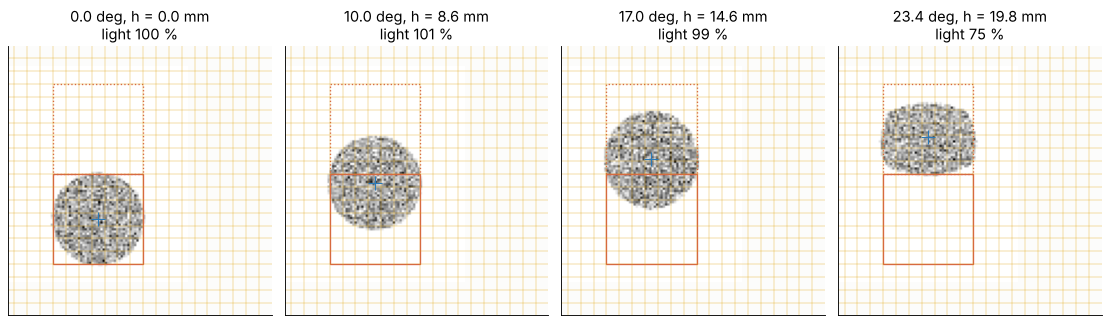

field   image height   centre of the microlens image (um)    theory f_m h/L   thin lens f_m h/f
 0.0       0.00 mm         -0.0                                   0.0               0.0
10.0       8.64 mm         39.6                                  39.6              48.4
17.0      14.60 mm         65.1                                  66.9              81.8
23.4      19.82 mm         87.8                                  90.8             111.0


In [15]:
# the double Gauss of notebook 90 at f/2.8 as the main lens; microlenses of 0.1 mm at f/2.8
lens = ph.double_gauss(2.8)
par = lens.paraxial()
f_m = 2.8*0.1
L = lens.image_z - par.xp_z
print("exit pupil %.1f mm in front of the image plane (a thin lens: %.1f mm)" % (L, par.efl))
fields = np.radians([0.0, 10.0, 17.0, 23.4])
rng = np.random.default_rng(4)
out = [lf.microlens_images(lens, fl, 0.1, f_m, n_rays=10000, rng=rng) for fl in fields]
n0 = len(out[0][0])

fig, axs = plt.subplots(1, 4, figsize=(14, 4.6))
ex = np.linspace(-0.1, 0.1, 81)
ey = np.linspace(-0.07, 0.17, 97)
for ax, fl, (xs, ys, hx, hy) in zip(axs, fields, out):
    H, _, _ = np.histogram2d(ys, xs, bins=[ey, ex])
    ax.imshow(H, origin="lower", extent=(ex[0], ex[-1], ey[0], ey[-1]), cmap="gray_r")
    for g in np.arange(-7, 13)*0.1/7 + 0.05/7:
        ax.axhline(g, color=ORANGE, lw=0.3)
        ax.axvline(g, color=ORANGE, lw=0.3)
    for y0 in (-0.05, 0.05):
        ax.add_patch(plt.Rectangle((-0.05, y0), 0.1, 0.1, fill=False, color=RED, lw=1.2,
                                   ls="-" if y0 < 0 else ":"))
    ax.plot(0, f_m*hy.mean()/L, "+", color=BLUE, ms=12)
    ax.set_title("%.1f deg, h = %.1f mm\nlight %.0f %%" % (np.degrees(fl), hy.mean(), 100*len(xs)/n0))
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

print("field   image height   centre of the microlens image (um)    theory f_m h/L   thin lens f_m h/f")
for fl, (xs, ys, hx, hy) in zip(fields, out):
    print("%4.1f     %6.2f mm       %6.1f                                %6.1f            %6.1f"
          % (np.degrees(fl), hy.mean(), 1e3*ys.mean(), 1e3*f_m*hy.mean()/L, 1e3*f_m*hy.mean()/par.efl))

The microlens images walk outward with the image height, by 88 µm
(6 pixels, nearly a whole microlens) in the corner of the frame. This is
within 3.5 % of $f_m h/L$, and the remaining difference is pupil
aberration. A pixel grid designed for $L = f$ would be off by another
23 µm, 1.6 pixels, in the corner. In the corner the clear apertures of
the lens also cut the pupil image (cat's eye vignetting, notebook 90),
and a quarter of the light is lost. The views whose pixels lie in the cut part
see nothing there.

A real plenoptic camera is therefore calibrated for each lens setting. A
white image locates the centre of every microlens image (Dansereau et al.
2013). A zoom lens changes $L$ with the focal length and the focus, so
the calibration depends on the lens setting. An image side telecentric main lens
($L \to \infty$) would put all the images on the microlens grid.

## Summary

- A microlens array in the image plane and a sensor in its focal plane
  record the light field: the microlens gives the position, and the pixel
  under it gives the part of the aperture. The microlens images just fill
  their cells when the F-numbers match ($f_m/p = v/D$). A faster main lens
  sends 37 % of the light (at f/2.8 for f/4.2 microlenses) to the wrong
  pixels.
- The pixels at the same place under all microlenses form a view through
  a part $\Delta u$ of the aperture. The disparity between views is
  $d = v\,\Delta u\,(1/s - 1/s_f)/p$, measured here to 0.002 microlenses,
  which gives depth to 0.5 % out to 3 m. Photo consistency across the
  views maps the depth of a whole scene.
- Shift-and-add refocusing on any plane gives the sharpness of a single
  view, $\vert\mathrm{sinc}(\nu)\,\mathrm{sinc}(d\nu)\vert$. The theory
  matches the rendered edges to 0.02 in MTF. The refocus range
  $\vert d\vert \le 1$ is the depth of field of f/$(nN)$ with $c = p$,
  from 0.49 m to infinity here, but with the light of f/$N$: 5.3 times
  less noise than f/28.
- The sensor's pixels are shared between positions and directions. The
  refocus range grows with $n$ and the resolution falls with $n$.
- With a real lens the microlens images sit at $f_m h/L$ from their
  microlenses, $L$ being the exit pupil distance (88 µm in the corner
  here, 3.5 % less than paraxial), and they are vignetted. The camera has
  to be calibrated with white images for each lens setting.

In [16]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 71 s


## References

- G. Lippmann, "Épreuves réversibles. Photographies intégrales",
  C. R. Acad. Sci. 146, 446–451 (1908).
- E. H. Adelson and J. Y. A. Wang, "Single lens stereo with a plenoptic
  camera", IEEE Trans. Pattern Anal. Mach. Intell. 14, 99–106 (1992).
- M. Levoy and P. Hanrahan, "Light field rendering", Proc. SIGGRAPH 96,
  31–42 (1996).
- R. Ng, M. Levoy, M. Brédif, G. Duval, M. Horowitz and P. Hanrahan, "Light
  field photography with a hand-held plenoptic camera", Stanford Tech.
  Report CTSR 2005-02 (2005).
- R. Ng, "Fourier slice photography", ACM Trans. Graph. 24, 735–744 (2005).
- R. Ng, *Digital Light Field Photography*, PhD thesis, Stanford
  University (2006).
- R. C. Bolles, H. H. Baker and D. H. Marimont, "Epipolar-plane image
  analysis: an approach to determining structure from motion", Int. J.
  Comput. Vis. 1, 7–55 (1987).
- B. D. Lucas and T. Kanade, "An iterative image registration technique
  with an application to stereo vision", Proc. IJCAI, 674–679 (1981).
- M. W. Tao, S. Hadap, J. Malik and R. Ramamoorthi, "Depth from combining
  defocus and correspondence using light-field cameras", Proc. ICCV,
  673–680 (2013).
- D. G. Dansereau, O. Pizarro and S. B. Williams, "Decoding, calibration
  and rectification for lenselet-based plenoptic cameras", Proc. CVPR,
  1027–1034 (2013).
- A. Lumsdaine and T. Georgiev, "The focused plenoptic camera", Proc. IEEE
  ICCP (2009).